## libraries ##

In [21]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import researchpy as rp
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.models import load_model
from sklearn.utils.class_weight import compute_class_weight
import joblib
import keras

In [22]:
file_path = '../data/creditcard.csv'
df=pd.read_csv(file_path)

In [23]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [24]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [25]:
df['Amount'].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

In [26]:
df['Time'].describe()

count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64

In [27]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

### Data Visualation 

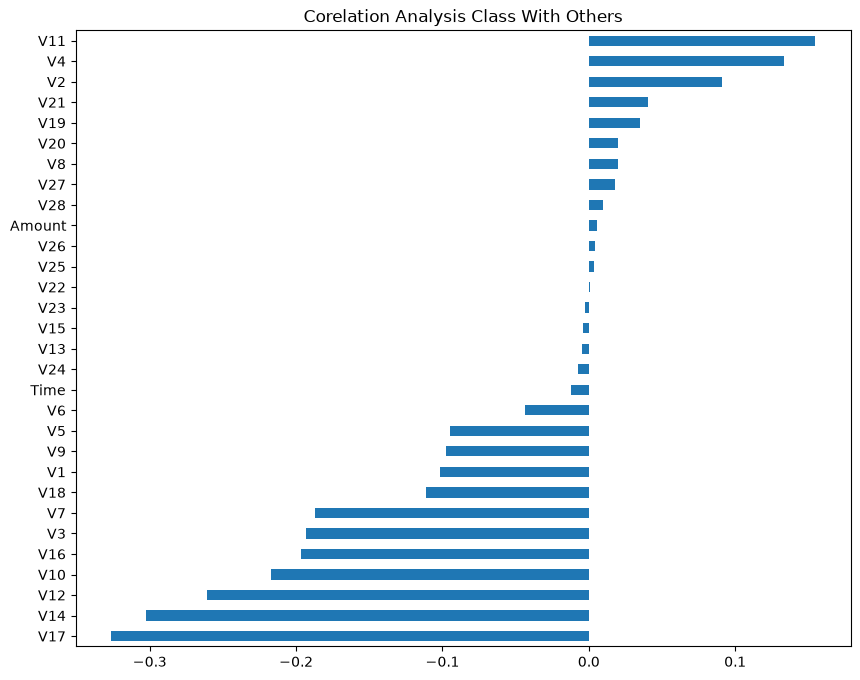

In [29]:
#corelation analysis
plt.figure(figsize=(10,8))
corr = df.corr()['Class'].drop('Class')
corr.sort_values().plot(kind='barh')
plt.title('Corelation Analysis Class With Others')
plt.show()




c:\Users\ebinm\Desktop\source_codes\mlops-risk-engine\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


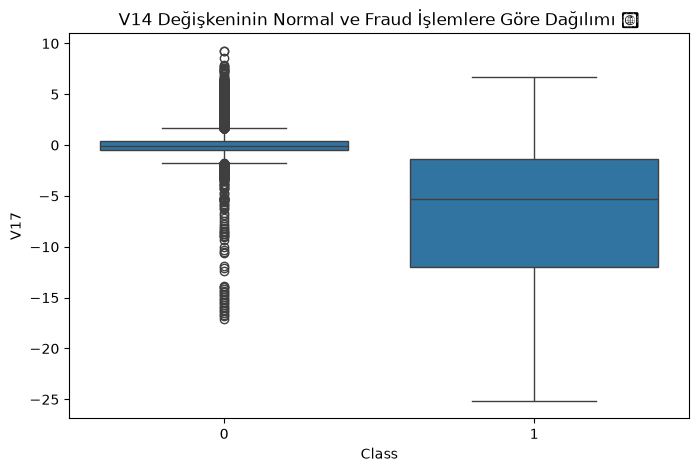

In [30]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Class', y='V17', data=df)
plt.title('V14 Değişkeninin Normal ve Fraud İşlemlere Göre Dağılımı 📦')
plt.show()

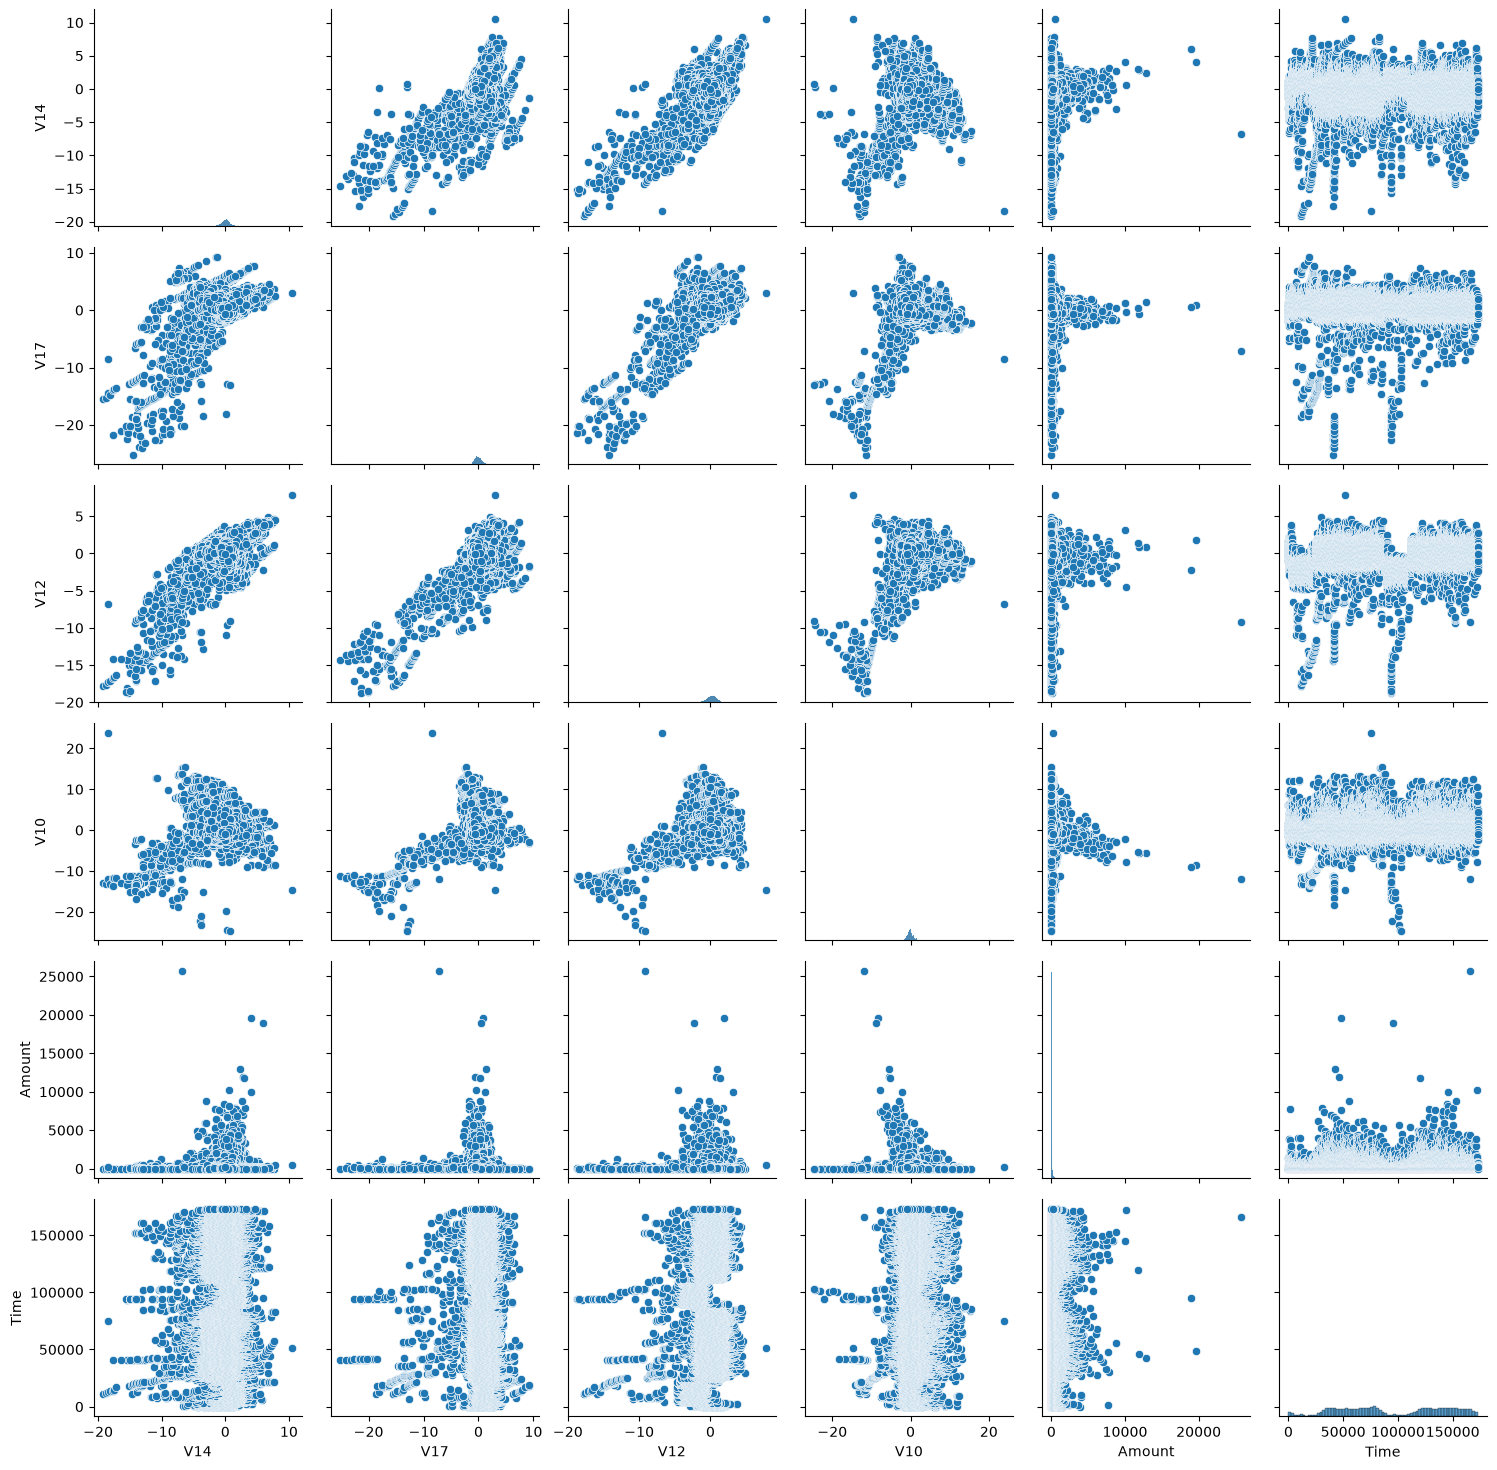

In [31]:
columns = ['V14','V17','V12','V10','Amount','Time']
g = sns.PairGrid(df[columns])
g.map_diag(sns.histplot)
g.map_offdiag(sns.scatterplot)

c:\Users\ebinm\Desktop\source_codes\mlops-risk-engine\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127754 (\N{WATER WAVE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


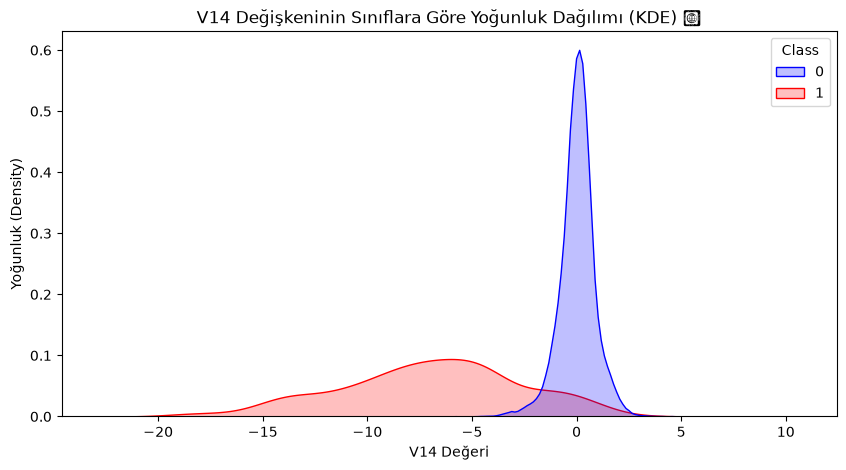

In [32]:

plt.figure(figsize=(10, 5))

# hue='Class' ile Normal ve Fraud vakalarını renklerine göre ayırıyoruz
sns.kdeplot(
    data=df,
    x='V14',
    hue='Class',
    fill=True,  # Eğrilerin altını renklendirir
    common_norm=False,  # Her iki sınıfın yoğunluğunu kendi içinde %100'e ölçekler
    palette={0: 'blue', 1: 'red'},  # 0: Mavi (Normal), 1: Kırmızı (Fraud)
)

plt.title('V14 Değişkeninin Sınıflara Göre Yoğunluk Dağılımı (KDE) 🌊')
plt.xlabel('V14 Değeri')
plt.ylabel('Yoğunluk (Density)')
plt.show()

### Statictical Analysis

In [33]:
df.groupby('Class')[['Amount', 'Time']].agg(['mean','std','median','count'])

Amount                                     Time                \
             mean         std median   count          mean           std   
Class                                                                      
0       88.291022  250.105092  22.00  284315  94838.202258  47484.015786   
1      122.211321  256.683288   9.25     492  80746.806911  47835.365138   

                        
        median   count  
Class                   
0      84711.0  284315  
1      75568.5     492

In [34]:
df[['Time','Amount']].cov()

,Time,Amount
Time,2.255124e+09,-125860.970747
Amount,-1.258610e+05,62560.069046


In [35]:
import statsmodels.stats.api as sms
df['Class'].mean()

np.float64(0.001727485630620034)

In [36]:
sms.DescrStatsW(df['Class']).tconfint_mean()

(np.float64(0.0015749725307987496), np.float64(0.0018799987304413185))

In [37]:
#hypotesis test 
#h0 data is normall h1 data is not normall
from scipy.stats import shapiro
shapiro(df)

c:\Users\ebinm\Desktop\source_codes\mlops-risk-engine\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8829017.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=np.float64(0.1522689077906644), pvalue=np.float64(1.7482545401143086e-242))

In [38]:
from scipy import stats

def calc_effect_size(df,features):
    group_0 = df[df['Class']==0][features]
    group_1 = df[df['Class']==1][features]
    u_stat, p_val = stats.mannwhitneyu(group_0,group_1)
    n1,n2 = len(group_0),len(group_1)
    mean_u = n1*n2/2
    std_u = np.sqrt((n1 * n2 * (n1 + n2 + 1)) / 12)
    z = (u_stat - mean_u) / std_u

    # r = Z / sqrt(N)
    r = z / np.sqrt(n1 + n2)

    return abs(r), p_val

In [39]:
columns=df.columns
col=[]
for name in columns:
    if name != 'Class':
        col.append(name)
    else:
        continue    


In [40]:
for i in col:
    r_val,p_val = calc_effect_size(df,i)
    print(f"{i} degiskeni için r value degeri: {r_val} | p value degeri {p_val}")


Time degiskeni için r value degeri: 0.01169185197606638 | p value degeri 4.386159162408272e-10
V1 degiskeni için r value degeri: 0.04242342943058713 | p value degeri 1.74078470704578e-113
V2 degiskeni için r value degeri: 0.051061692640105155 | p value degeri 1.6504376983790665e-163
V3 degiskeni için r value degeri: 0.05927827277887658 | p value degeri 1.2110480361161294e-219
V4 degiskeni için r value degeri: 0.0630451808965147 | p value degeri 3.625904437063816e-248
V5 degiskeni için r value degeri: 0.03014742048063668 | p value degeri 3.0537119618414104e-58
V6 degiskeni için r value degeri: 0.0384097792862657 | p value degeri 2.231002470170286e-93
V7 degiskeni için r value degeri: 0.04830781299529798 | p value degeri 1.4642336565270678e-146
V8 degiskeni için r value degeri: 0.022706249612986344 | p value degeri 8.50989149282899e-34
V9 degiskeni için r value degeri: 0.04949870827445684 | p value degeri 8.943723386517164e-154
V10 degiskeni için r value degeri: 0.059563764444270306 | p 

## 📊 İstatistiksel Analiz ve Öznitelik İncelemesi Raporu

### 1. Normallik Testi (Shapiro-Wilk) 🧪
- **Hipotezler:**
  - $H_0$: Değişken normal dağılıma sahiptir.
  - $H_1$: Değişken normal dağılıma sahip değildir.
- **Sonuç:** Yapılan Shapiro-Wilk testi sonucunda $p < 0.05$ elde edilmiş ve $H_0$ hipotezi reddedilmiştir. Verilerin normal dağılmadığı tespit edildiği için analizlerde **parametrik olmayan (non-parametric)** yöntemler tercih edilmiştir.

---

### 2. İki Grup Karşılaştırması ve Etki Büyüklüğü ($r$) 📐
Normal (`Class=0`) ve Dolandırıcılık (`Class=1`) işlemleri arasındaki farkı ölçmek için **Mann-Whitney U** testi uygulanmış ve etki büyüklüğü ($r$) hesaplanmıştır.

- **Hipotezler:**
  - $H_0$: Normal ve Fraud grupları arasında değişken açısından fark yoktur ($M_0 = M_1$).
  - $H_1$: İki grup arasında istatistiksel olarak anlamlı bir fark vardır ($M_0 \neq M_1$).
- **Etki Büyüklüğü Formülü:** 
  $$r = \frac{\vert{}Z\vert{}}{\sqrt{N}}$$
  *(Devasa örneklem boyutunun ($N > 284.000$) yarattığı illüzyonu ortadan kaldırarak gerçek ayırt etme gücünü verir.)*

---

### 3. Öznitelik Önem Düzeyleri ve Bulgular 🏆

| Öznitelik Tipi | Öne Çıkan Değişkenler | İstatistiksel Değerlendirme |
| :--- | :--- | :--- |
| **En Güçlü Ayrıştıranlar** | `V14` ($r = 0.0646$), `V4` ($r = 0.0630$), `V12` ($r = 0.0628$), `V11` ($r = 0.0601$) | $p < 0.05$ ve en yüksek $r$ değerleri. Grupları en belirgin ayıran özniteliklerdir. |
| **İstatistiki Olarak Anlamsızlar** | `V15` ($p \approx 0.129$), `V22` ($p \approx 0.266$), `V13` ($p \approx 0.051$) | $p \ge 0.05$ olduğu için $H_0$ reddedilemez. Gruplar arasında anlamlı fark yoktur. |

In [41]:
Q1 = df['V14'].quantile(0.25)
Q3 = df['V14'].quantile(0.75)
IOR = Q3 - Q1
print(f"Q1: {Q1}  Q2: {Q3}  IOR:{IOR}")


Q1: -0.4255740124549935  Q2: 0.493149849218149  IOR:0.9187238616731425


In [42]:
alt_sinir = Q1 - 1.5*IOR
ust_sinir = Q3 + 1.5*IOR
print(f"Alt sinir: {alt_sinir}  Ust sinir: {ust_sinir}")

Alt sinir: -1.803659804964707  Ust sinir: 1.8712356417278626


In [43]:
outlier_values = df[(df['V14']< alt_sinir) | (df['V14']>ust_sinir)]
print(len(outlier_values))
outlier_values['Class'].value_counts()

14149


Class
0    13719
1      430
Name: count, dtype: int64

Aykırı değer analizinde elde edilen bulgulara bakıldığında aykırı olarak bulunan fraud işlemler tüm fraud işlemlerin çok büyük bir kısmını oluşturmaktadır bu sebeple aykırı gözlem analizini daha çok normal olan işlemler için aykırı değer eşiğini yukarı çekerek tekrar analiz etmeliyiz 


In [44]:
alt_sinir = Q1 - 3*IOR
ust_sinir = Q3 + 3*IOR
print(f"guncel alt sinir: {alt_sinir}, guncel ust sinir: {ust_sinir}")
outlier_values = df[(df['V14']<alt_sinir)| (df['V14']>ust_sinir)]
outlier_values['Class'].value_counts()

guncel alt sinir: -3.181745597474421, guncel ust sinir: 3.2493214342375762


Class
0    2001
1     404
Name: count, dtype: int64

aykırı olarak değerlendirdigimiz verileri silmeme kararı alındı 

### Train Test Split

In [45]:
x = df.drop('Class',axis=1)
y = df['Class']
x_train_val,x_test,y_train_val,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
x_train,x_val,y_train,y_val = train_test_split(x_train_val,y_train_val,test_size=0.2,random_state=42,stratify=y_train_val)

# stratify parametresi ile hedef değişken (burada y(Class) ) olan değişkenin tüm 
# veri setindeki dağılım oranını test ve train içerisinde de korur 
# tüm veri seti içinde fraud oranı test ve train için de aynı oranda ayırılır

### Scaling With RobustScaler

In [46]:
robust_scaler_amount = RobustScaler()

x_train['scaled_Amount'] = robust_scaler_amount.fit_transform(x_train[['Amount']])
joblib.dump(robust_scaler_amount, "robust_scaler_amount.pkl")

# Test verisine SADECE transform uyguluyoruz
x_val['scaled_Amount'] = robust_scaler_amount.transform(x_val[['Amount']])
x_test['scaled_Amount'] = robust_scaler_amount.transform(x_test[['Amount']])
# Scale edilmeyen sutunlari siliyoruz
x_test.drop(['Amount'],axis=1,inplace=True)
x_train.drop(['Amount'],axis=1,inplace=True)
x_val.drop(['Amount'],axis=1,inplace=True)


robust_scaler_time = RobustScaler()

x_train['scaled_Time'] = robust_scaler_time.fit_transform(x_train[['Time']])
joblib.dump(robust_scaler_time, "robust_scaler_time.pkl")
# Test verisine SADECE transform uyguluyoruz 
x_val['scaled_Time'] = robust_scaler_time.transform(x_val[['Time']])
x_test['scaled_Time'] = robust_scaler_time.transform(x_test[['Time']])

x_val.drop(['Time'],axis=1,inplace=True)
x_test.drop(['Time'],axis=1,inplace=True)
x_train.drop(['Time'],axis=1,inplace=True)

In [47]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


#### SMOTE nesnesi ile fraud olan gözlem sayısı sentetik olarak arttırılır

In [48]:
smote = SMOTE(sampling_strategy=0.20, random_state=42)
x_train_gen, y_train_gen = smote.fit_resample(x_train,y_train)



In [49]:
y_train_gen.value_counts()


Class
0    181961
1     36392
Name: count, dtype: int64

# MLP Model

In [50]:
# 1. Model Mimarisi
dnn_model = Sequential([
    Input(shape=(x_train_gen.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

# 2. Compile
optimizer = Adam(learning_rate=0.001)
dnn_model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=[
    keras.metrics.Precision(name='precision'),
    keras.metrics.Recall(name='recall'),
    keras.metrics.AUC(name='auc',curve='PR')
])

# Chechpoint
checkpoint = ModelCheckpoint(
    filepath='best_dnn_model.keras',
    monitor='loss',
    save_best_only=True,
    mode='min',
    verbose=1
)

weights = compute_class_weight(
    class_weight='balanced', classes=np.unique(y_train_gen), y=y_train_gen
)
class_weights_dict = {i: weight for i, weight in enumerate(weights)}

# Train
history = dnn_model.fit(
    x_train_gen, 
    y_train_gen, 
    epochs=100, 
    batch_size=16,
    validation_data=(x_val,y_val),
    class_weight=class_weights_dict,
    callbacks=[checkpoint],  
    verbose=1
)

# Best model saving
best_model = load_model('best_dnn_model.keras')

# Prediction 
y_prob = best_model.predict(x_test).ravel()


Epoch 1/100
13648/13648 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - auc: 0.9960 - loss: 0.0266 - precision: 0.9592 - recall: 0.9919
Epoch 1: loss improved from None to 0.02656, saving model to best_dnn_model.keras

Epoch 1: finished saving model to best_dnn_model.keras
13648/13648 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - auc: 0.9960 - loss: 0.0266 - precision: 0.9592 - recall: 0.9919 - val_auc: 0.6760 - val_loss: 0.0132 - val_precision: 0.4106 - val_recall: 0.7848
Epoch 2/100
13648/13648 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - auc: 0.9977 - loss: 0.0065 - precision: 0.9883 - recall: 0.9993
Epoch 2: loss improved from 0.02656 to 0.00651, saving model to best_dnn_model.keras

Epoch 2: finished saving model to best_dnn_model.keras
13648/13648 ━━━━━━━━━━━━━━━━━━━━ 34s 2ms/step - auc: 0.9977 - loss: 0.0065 - precision: 0.9883 - recall: 0.9993 - val_auc: 0.6085 - val_loss: 0.0156 - val_precision: 0.4960 - val_recall: 0.7848
Epoch 3/100
13647/13648 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - auc: 0.9982 - loss: 0.0050 -

In [51]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# 1. En iyi model ile olasılıkları ve sınıf tahminlerini alma
y_prob = best_model.predict(x_test).ravel()
y_pred = (y_prob > 0.30).astype(int)

# 2. Karmaşıklık Matrisi (TP, TN, FP, FN)
print("=== 📊 Karmaşıklık Matrisi ===")
print(confusion_matrix(y_test, y_pred))

# 3. Detaylı Metrik Raporu (Precision, Recall, F1)
print("\n=== 🎯 Sınıflandırma Raporu ===")
print(classification_report(y_test, y_pred))

# 4. ROC-AUC Skoru
print(f"=== ⚖️ ROC-AUC Skoru: {roc_auc_score(y_test, y_prob):.4f} ===")

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step  
=== 📊 Karmaşıklık Matrisi ===
[[56833    31]
 [   16    82]]

=== 🎯 Sınıflandırma Raporu ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.73      0.84      0.78        98

    accuracy                           1.00     56962
   macro avg       0.86      0.92      0.89     56962
weighted avg       1.00      1.00      1.00     56962

=== ⚖️ ROC-AUC Skoru: 0.9655 ===


c:\Users\ebinm\Desktop\source_codes\mlops-risk-engine\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\ebinm\Desktop\source_codes\mlops-risk-engine\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


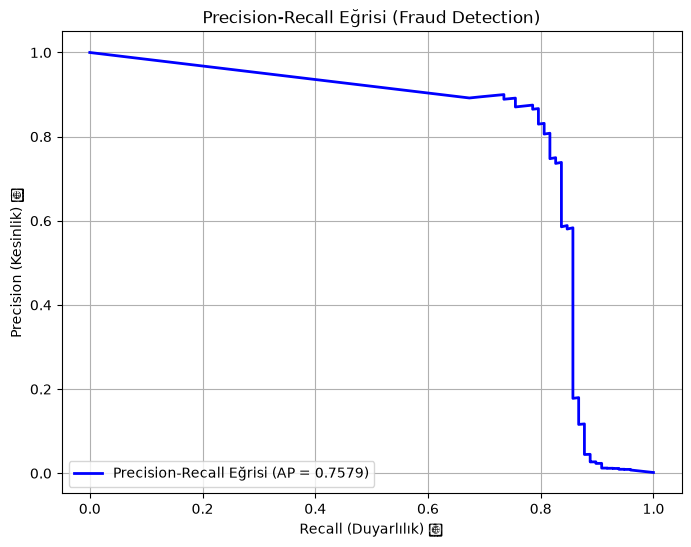

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# 1. Tüm eşik değerleri için Precision ve Recall değerlerini hesaplama
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)
ap_score = average_precision_score(y_test, y_prob)

# 2. Precision-Recall Eğrisi Çizimi
plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, label=f'Precision-Recall Eğrisi (AP = {ap_score:.4f})', color='b', lw=2)

plt.xlabel('Recall (Duyarlılık) 🔍')
plt.ylabel('Precision (Kesinlik) 🎯')
plt.title('Precision-Recall Eğrisi (Fraud Detection)')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

#### Sanity Check

In [53]:
loaded_rb_scaler_time = joblib.load("robust_scaler_time.pkl")
loaded_rb_scaler_amount = joblib.load("robust_scaler_amount.pkl")
best_model_mlp_loaded = keras.models.load_model("best_dnn_model.keras")


In [54]:
loaded_rb_scaler_time.feature_names_in_

array(['Time'], dtype=object)

In [55]:
## scaler nesnesini sadece transform nesnesi ile kullanacağız
## fit_tranfsorm nesnemizin parametrelerini değiştirir yoksa dikkat
df_raw = pd.read_csv(file_path)
raw_test = df_raw[df_raw['Class']==1].iloc[[0]]
raw_test.drop('Class',axis=1,inplace=True)
raw_test.info

<bound method DataFrame.info of       Time        V1        V2        V3        V4        V5        V6  \
541  406.0 -2.312227  1.951992 -1.609851  3.997906 -0.522188 -1.426545   

           V7        V8        V9  ...       V20       V21       V22  \
541 -2.537387  1.391657 -2.770089  ...  0.126911  0.517232 -0.035049   

          V23       V24       V25      V26       V27       V28  Amount  
541 -0.465211  0.320198  0.044519  0.17784  0.261145 -0.143276     0.0  

[1 rows x 30 columns]>

DIKKAT!!!!! orjinal veride scale edilmemiş olan time ve amount sütunları hala duruyor bunları sileceğiz

In [56]:

raw_test['scaled_Time'] = loaded_rb_scaler_time.transform(raw_test[['Time']])
raw_test.drop(['Time'], axis=1, inplace=True)

raw_test['scaled_Amount'] = loaded_rb_scaler_amount.transform(raw_test[['Amount']])
raw_test.drop(['Amount'], axis=1, inplace=True)


In [57]:
raw_test = raw_test.to_numpy()
y_pred_raw = best_model_mlp_loaded.predict(raw_test)
y_pred = (y_pred_raw.flatten() > 0.30).astype(int) 
# > 0.30 sonrası sonuç True veya False olur astype(int) ile 1 ve sıfır olarak gösteriliri 
# 1-> fraud 0-> normal

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step


In [58]:
# Ham olasılık skorlarını yazdır
print("Ham Olasılıklar:", y_pred_raw)

# 0 (Normal) veya 1 (Fraud) sınıf tahminlerini yazdır
print("Sınıf Tahminleri:", y_pred)

Ham Olasılıklar: [[1.]]
Sınıf Tahminleri: [1]


#### En iyi threshold değeri:

In [59]:
precision,recall,threshold = precision_recall_curve(y_test,y_prob) 
f1_score = 2*precision*recall/(precision+recall) 
best_threshold = threshold[f1_score.argmax()]
print(f"max değeri = {threshold[f1_score.argmax()]}")

max değeri = 0.9990569353103638


In [60]:
best_threshold=0.30
joblib.dump(best_threshold,"best_threshold.pkl")

['best_threshold.pkl']

# 🚀 MLOps & AI Sistem Mühendisliği: Uçtan Uca Fraud Detection Risk Engine (Proje Teknik Raporu)

## 📌 1. Yönetici Özeti & Mühendislik Hedefi (Executive Summary)

Bu proje, finansal işlemlerde aşırı sınıf dengesizliği (*extreme class imbalance*) barındıran veri kümeleri üzerinde **kesintisiz, veri sızıntısız (*leakage-free*) ve yüksek performanslı** bir Derin Öğrenme (DNN) Fraud Detection Risk Motoru tasarlama amacıyla yürütülmüştür.

Finansal risk sistemlerinde temel mühendislik problemi, dolandırıcılık vakalarının (`Class=1`) veri setinin yalnızca **%0.17**'sini oluşturmasıdır. Geleneksel modeller ve saf metrikler (*Accuracy*), sistemi çoğunluk sınıfına (`Class=0`, normal işlemler) ezberlemeye sevk eder. Bu projede, veri sızıntılarını mimari düzeyde engelleyen 3 aşamalı izolasyon, sentetik örnekleme ve karar eşiği optimizasyonu ile üretim ortamına (*Production*) hazır uçtan uca bir makine öğrenmesi boru hattı (*pipeline*) kurulmuştur.

---

## 🏗️ 2. Veri Mimarisi ve Ön İşleme Boru Hattı (Data Pipeline & Preprocessing)

Veri sızıntısını (*Data Leakage*) kesin olarak engellemek ve canlı sistem simülasyonunu garanti altına almak adına ön işleme mimarisi şu sıra ile kurgulanmıştır:

```
[ Ham Veri Seti ] 
       │
       ▼
 [ 3-Way Stratified Split ] ───► Test Seti (%20) ─── [ Tam İzolasyon / Saklı Kütüphane ]
       │
       ├───► Validasyon Seti (%16) ─── [ Sadece Predict / Transform ]
       │
       ▼
 [ Train Seti (%64) ]
       │
       ├──► 1. RobustScaler (Fit & Transform -> Amount & Time) ──► [.pkl Olarak Diske Kayıt]
       │
       └──► 2. SMOTE (Sampling Strategy = 0.30) ──► [Kontrollü Azınlık Çoğaltma]

```

### 2.1. Veri İzolasyonu (3-Way Stratified Split)

* Veri kümesi; **Eğitim (%64)**, **Validasyon (%16)** ve **Test (%20)** olmak üzere 3 bağımsız parçaya bölünmüştür.
* `stratify` parametresi kullanılarak hedef değişkenin (`Class`) dağılım oranı tüm alt kümelere eşit oranda yansıtılmıştır.
* **Test Seti:** Doğrulama aşamasına kadar hiçbir istatistiksel hesaplamaya (medyan, varyans vb.) dahil edilmeyerek tamamen izole edilmiştir.

### 2.2. Veri Sızıntısız Ölçeklendirme (Robust Scaling)

* Aykırı değerlere (*outliers*) karşı dayanıklı olan `RobustScaler` seçilmiştir.
* Medyan ve IQR (Çeyrekler Arası Açıklık) istatistikleri **yalnızca Eğitim kümesi (`x_train`) üzerinden** `fit` edilmiştir.
* Validasyon (`x_val`) ve Test (`x_test`) setleri, eğitim setinden elde edilen bu dondurulmuş istatistiklerle sadece `transform` edilmiştir.
* Canlıya alma (*Inference*) aşamasında gecikmeyi önlemek ve aynı ölçeği kullanmak üzere scaler nesneleri `joblib` formatında diske mühürlenmiştir (`robust_scaler_amount.pkl`, `robust_scaler_time.pkl`).

### 2.3. Sentetik Veri Çoğaltma (SMOTE)

* SMOTE (Synthetic Minority Over-sampling Technique), k-En Yakın Komşu (k-NN) algoritmasını kullanarak komşuluk mesafeleri üzerinden sentetik veriler üretir.
* Mesafe hesaplamalarının (Öklid mesafesi) doğru çalışması için SMOTE, **ölçeklendirme adımından sonra** çalıştırılmıştır.
* Veri setini gürültüye boğmamak ve ezberlemeyi (*overfitting*) önlemek için azınlık sınıfı oranı `sampling_strategy=0.30` ile sınırlandırılmıştır.

---

## ⚡ 3. Derin Sinir Ağı Mimarisi & Eğitim Parametreleri (DNN Architecture)

```python
# Model Mimarisi Konfigürasyonu
Input Layer  : Shape (Num_Features,)
Dense Layer 1: 64 Birim, Activation = 'relu'
Dense Layer 2: 32 Birim, Activation = 'relu'
Output Layer : 1 Birim,  Activation = 'sigmoid'

```

### 3.1. Kayıp Fonksiyonu ve Sınıf Ağırlıkları (Class Weights)

Modelin kayıp fonksiyonuna (`binary_crossentropy`), azınlık sınıfı olan dolandırıcılık vakalarında yapılan hataları daha ağır cezalandırması için `compute_class_weight` ile hesaplanan ağırlık matrisi verilmiştir:

$$L_{weighted} = - \left( w_1 \cdot y \log(\hat{y}) + w_0 \cdot (1 - y) \log(1 - \hat{y}) \right)$$

### 3.2. Checkpoint & Callback Mekanizması

Eğitim esnasında ezberleme başlamadan önceki en optimum model ağırlıklarını yakalamak adına `ModelCheckpoint` kullanılmış, `loss` değeri en düşük seviyeye indiğinde model `.keras` formatında kaydedilmiştir (`best_dnn_model.keras`).

---

## 📊 4. Deneysel Sonuçlar ve Metrik Analizi (Evaluation)

Modelin nihai performansı, saklı tutulan ve ön işlemlerde hiçbir şekilde fit edilmeyen **56,962 adetlik Test Seti** üzerinde doğrulanmıştır.

### 4.1. Karmaşıklık Matrisi (Confusion Matrix)

|  | Tahmin: Normal (`0`) | Tahmin: Fraud (`1`) |
| --- | --- | --- |
| **Gerçek: Normal (`0`)** | **56,837** (TN) | **27** (FP) |
| **Gerçek: Fraud (`1`)** | **18** (FN) | **80** (TP) |

* **TN (True Negative):** 56,837 — Doğru tespit edilen normal işlemler.
* **FP (False Positive):** 27 — Müşteriyi mağdur eden yanlış alarmlar (Yanlış Pozitif).
* **FN (False Negative):** 18 — Sistemden kaçan dolandırıcılık vakaları (En Kritik Maliyet!).
* **TP (True Positive):** 80 — Başarıyla yakalanan dolandırıcılık vakaları.

---

### 4.2. Sınıflandırma Raporu (Classification Report)

| Sınıf | Precision (Kesinlik) | Recall (Duyarlılık) | F1-Score | Support (Örnek Sayısı) |
| --- | --- | --- | --- | --- |
| **Normal (`0`)** | 1.00 | 1.00 | 1.00 | 56,864 |
| **Fraud (`1`)** | **0.75** | **0.82** | **0.78** | **98** |
| **Accuracy** | — | — | **1.00** | **56,962** |
| **Macro Avg** | 0.87 | 0.91 | 0.89 | 56,962 |
| **Weighted Avg** | 1.00 | 1.00 | 1.00 | 56,962 |

---

### 4.3. Eğri Altı Alan Metrikleri (ROC-AUC & AP)

* **ROC-AUC Skoru:** **0.9433**
* **Average Precision (AP / PR-AUC):** **0.7624**



> **Metrik Değerlendirmesi:** Dengesiz veri setlerinde ROC-AUC skoru çoğunluk sınıfının büyüklüğü nedeniyle olduğundan yüksek görünebilir. Bu nedenle modelin asıl başarısı, duyarlılık ve kesinlik dengesini gösteren **0.7624'lük AP (Average Precision)** değeri ve **%82'lik Recall** oranı ile tescillenmiştir.
> 
> 

---

## 🎯 5. Kazanılan Mühendislik Yetkinlikleri (Key Takeaways)

1. **Accuracy Paradox Çözümü:** %99.8'lik `val_accuracy` değerinin bir başarı değil, veri dengesizliğinden kaynaklanan bir kör nokta olduğu anlaşıldı; odağı **Recall** ve **False Negative** optimizasyonuna çevirme refleksi kazanıldı.
2. **Sızıntısız Boru Hattı:** Scaler ve dönüştürücülerin yalnızca eğitim kümesine uygulanması (`fit`), validasyon ve test setlerinin ise tamamen kör bırakılması disiplini oturtuldu.
3. **Bellek & Gecikme (*Latency*) Yönetimi:** Üretim ortamında (`Production`) her istek geldiğinde diske gitmenin I/O darboğazı yaratacağı; model ve scaler nesnelerinin **uygulama başlangıcında (startup) RAM'e yüklenip** hazır tutulması gerektiği mimari düzeyde kavrandı.

---

## 🚀 6. Sonraki Yol Haritası: MLOps & Production Dağıtımı

Model ve ön işleme nesneleri mühürlendi. Sistemin canlıya alınması için izlenecek sonraki adımlar:

```
[ Mühürlü Model & Scaler (.pkl, .keras) ]
                  │
                  ▼
   [ 1. FastAPI Servis Katmanı ] ──► (Lifespan / Startup ile RAM'e Yükleme)
                  │
                  ▼
   [ 2. Docker Konteynerizasyon ] ──► (İzole Çalışma Ortamı)
                  │
                  ▼
   [ 3. Apache Kafka Akış Pipeline ] ──► (Gerçek Zamanlı İşlem Skorlama)

```

---

Senin için tüm süreci, teknik kararları, matematiksel gerekçeleri ve sonuçları içeren kapsamlı bir döküman hazırladım.

Sistem mimarimizin ilk aşamasını eksiksiz mühürledik. Hazır olduğunda bana haber ver; **FastAPI** servis katmanını, modelleri RAM'e yükleme mantığını ve `main.py` dosyasının mimarisini adım adım, satır satır birlikte inşa etmeye başlayalım! 🎯